# NOTEBOOK 03: HUẤN LUYỆN MÔ HÌNH PHÂN LOẠI TẦNG 1 & PHÂN TÍCH LỖI CHUYÊN SÂU (OULAD)

**Dự án:** Hệ thống Cảnh báo sớm Học vụ và Mô phỏng Kịch bản Học tập 2 Tầng (What-If Simulator)

**Mục tiêu EPIC 3:**
- **Task 3.1:** Thiết lập Pipeline Tiền xử lý chuẩn mực (`StandardScaler` + `SMOTE`) chống rò rỉ dữ liệu (Anti-Data Leakage), huấn luyện mô hình Baseline `LogisticRegression` trên tập Train (70%) và đánh giá trên tập Dev (15%).
- **Task 3.2:** Huấn luyện, tối ưu siêu tham số với `RandomForestClassifier` và `XGBClassifier`, tinh chỉnh ngưỡng cảnh báo (Threshold Tuning trên tập Dev) để đảm bảo độ nhạy **Recall >= 0.85**.
- **Task 3.3:** Phân tích lỗi định lượng chuyên sâu (Cohort Error Analysis: Khảo sát chi tiết nhóm False Negative - bỏ sót nguy cơ và False Positive - báo động nhầm).
- **Task 3.4:** Đánh giá chốt hạ trên tập Test (15%) và đóng gói Pipeline tối ưu ra file `models/pipeline_stage1_dropout.pkl` kèm `models/model_metadata.json`.

---
## 🚨 EPIC 3: HUẤN LUYỆN TẦNG 1 & PHÂN TÍCH LỖI CHUYÊN SÂU
### 🔹 Task 3.1: Thiết lập Pipeline Tiền xử lý & Cân bằng nhãn (SMOTE) trên tập Train (70%)

> ⚠️ **Nguyên tắc Sống còn - Chống Rò rỉ Dữ liệu (Anti-Data Leakage):**
>
> 1. **Chỉ `fit` và `resample` trên tập Train 70%:** Bộ chuẩn hóa `StandardScaler` (tính $\mu, \sigma$) và thuật toán sinh mẫu `SMOTE` (nội suy k-NN) tuyệt đối chỉ được học trên `stage1_train.csv`.
> 2. **Giữ nguyên phân phối thực tế của tập Dev (15%) và Test (15%):** Tuyệt đối **không được áp dụng SMOTE** lên tập Dev hoặc Test. Tập kiểm định và tập kiểm tra phải phản ánh chân thực phân phối sinh viên trong môi trường thực tế.
> 3. **Bắt buộc dùng `imblearn.pipeline.Pipeline`:** Khác với thư viện `sklearn.pipeline.Pipeline` vốn không hỗ trợ can thiệp mẫu nhãn ở các bước trung gian, `imblearn.pipeline.Pipeline` sẽ tự động kích hoạt `fit_resample` khi huấn luyện (`fit`), nhưng tự động bỏ qua bước SMOTE khi thực hiện suy luận (`predict` / `predict_proba`) trên tập Dev và Test.

In [1]:
# CELL 1: Import thư viện và thiết lập cấu hình đường dẫn chuẩn
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thư viện Pipeline & Imbalanced Learning
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Xác định PROJECT_ROOT linh hoạt (hoạt động chuẩn dù chạy từ root hay trong thư mục notebooks/)
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
SPLITS_DIR = os.path.join(PROJECT_ROOT, 'data', 'splits')
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
MODELS_DIR = os.path.join(PROJECT_ROOT, 'models')
ERROR_LOGS_DIR = os.path.join(PROJECT_ROOT, 'reports', 'error_logs')

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(ERROR_LOGS_DIR, exist_ok=True)

# Thiết lập thẩm mỹ đồ thị
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'

print("✅ Môi trường huấn luyện Task 3.1 đã sẵn sàng!")
print(f"   PROJECT_ROOT: {PROJECT_ROOT}")
print(f"   Thư mục splits: {SPLITS_DIR}")

✅ Môi trường huấn luyện Task 3.1 đã sẵn sàng!
   PROJECT_ROOT: D:\What-If Simulator
   Thư mục splits: D:\What-If Simulator\data\splits


### 3.1.1. Nạp tập Train (70%) và Dev (15%) đã cố định từ Task 2.2

Danh sách 10 đặc trưng chính Tầng 1 (`FEATURES_T1`):
1. `weighted_final_score`: Điểm quá trình có trọng số theo quy chuẩn tín chỉ Việt Nam (thang 10).
2. `gpa_credits`: Chỉ số tải trọng tín chỉ & rủi ro tích lũy.
3. `gap_process_exam`: Độ lệch phong độ đầu kỳ vs. giai đoạn nước rút cuối kỳ.
4. `submitted_count`: Tổng số bài tập/bài kiểm tra đã nộp.
5. `attendance_rate`: Tỷ lệ phần trăm chuyên cần quy đổi từ hoạt động VLE.
6. `total_clicks`: Tổng số lượt click tương tác học liệu trực tuyến.
7. `num_of_prev_attempts`: Số lần từng học lại môn này.
8. `studied_credits`: Số tín chỉ đang học trong kỳ.
9. `vle_engagement_score`: Điểm tương tác học tập trung bình mỗi ngày hoạt động.
10. `vle_drop_ratio`: Tỷ lệ sụt giảm tương tác giai đoạn cuối kỳ so với đầu kỳ.

Nhãn mục tiêu: `is_dropout` (1 = Nguy cơ bỏ học/rớt môn, 0 = An toàn/qua môn).

In [2]:
# CELL 2: Nạp dữ liệu Train 70% và Dev 15%
train_df = pd.read_csv(os.path.join(SPLITS_DIR, 'stage1_train.csv'))
dev_df   = pd.read_csv(os.path.join(SPLITS_DIR, 'stage1_dev.csv'))

TARGET_T1 = 'is_dropout'
FEATURES_T1 = [col for col in train_df.columns if col != TARGET_T1]

X_train, y_train = train_df[FEATURES_T1], train_df[TARGET_T1]
X_dev, y_dev     = dev_df[FEATURES_T1], dev_df[TARGET_T1]

# Kiểm tra toàn vẹn dữ liệu (không có missing values)
assert X_train.isna().sum().sum() == 0, "❌ Lỗi: X_train có chứa giá trị thiếu (NaN)!"
assert X_dev.isna().sum().sum() == 0, "❌ Lỗi: X_dev có chứa giá trị thiếu (NaN)!"

print("✅ Nạp dữ liệu phân tầng thành công:")
print(f"   📦 X_train: {X_train.shape[0]:,} dòng x {X_train.shape[1]} đặc trưng")
print(f"      - Lớp 0 (An toàn):       {(y_train == 0).sum():,} dòng ({(y_train == 0).mean():.1%})")
print(f"      - Lớp 1 (Nguy cơ rớt):   {(y_train == 1).sum():,} dòng ({(y_train == 1).mean():.1%})")
print(f"   📦 X_dev:   {X_dev.shape[0]:,} dòng x {X_dev.shape[1]} đặc trưng")
print(f"      - Lớp 0 (An toàn):       {(y_dev == 0).sum():,} dòng ({(y_dev == 0).mean():.1%})")
print(f"      - Lớp 1 (Nguy cơ rớt):   {(y_dev == 1).sum():,} dòng ({(y_dev == 1).mean():.1%})")

✅ Nạp dữ liệu phân tầng thành công:
   📦 X_train: 22,815 dòng x 10 đặc trưng
      - Lớp 0 (An toàn):       10,769 dòng (47.2%)
      - Lớp 1 (Nguy cơ rớt):   12,046 dòng (52.8%)
   📦 X_dev:   4,889 dòng x 10 đặc trưng
      - Lớp 0 (An toàn):       2,308 dòng (47.2%)
      - Lớp 1 (Nguy cơ rớt):   2,581 dòng (52.8%)


### 3.1.2. Xây dựng Pipeline Tiền xử lý & Cân bằng nhãn (SMOTE)

Cấu trúc Pipeline:
$$\text{X\_train} \xrightarrow{\text{StandardScaler}} \text{Z-score Scaled} \xrightarrow{\text{SMOTE(random\_state=42)}} \text{Balanced 50:50} \xrightarrow{\text{LogisticRegression}} \hat{y}$$

- **StandardScaler:** Đưa tất cả 10 đặc trưng về cùng thang chuẩn hóa (trung bình 0, độ lệch chuẩn 1), giúp hàm mất mát của `LogisticRegression` hội tụ nhanh và hệ số $\beta$ phản ánh chính xác mức độ quan trọng tương đối giữa các đặc trưng.
- **SMOTE:** Tạo thêm các mẫu tổng hợp cho nhóm thiểu số bằng nội suy hình học giữa các láng giềng k-NN, cân bằng tỷ lệ mẫu giúp mô hình không bị thiên vị về nhóm đa số.
- **LogisticRegression (Baseline):** Sử dụng siêu tham số `max_iter=1000, random_state=42` làm mô hình mốc chuẩn mực.

In [3]:
# CELL 3: Xây dựng Pipeline imblearn và Huấn luyện mô hình Baseline
baseline_pipeline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

print("⏳ Đang huấn luyện Baseline Pipeline trên tập Train 70%...")
baseline_pipeline.fit(X_train, y_train)
print("✅ Huấn luyện Baseline Logistic Regression hoàn tất thành công!")

⏳ Đang huấn luyện Baseline Pipeline trên tập Train 70%...


✅ Huấn luyện Baseline Logistic Regression hoàn tất thành công!


### 3.1.3. Đánh giá Hiệu năng Mô hình Baseline trên tập Dev (15%)

Kiểm tra mô hình trên tập Dev để trả lời câu hỏi cốt lõi:
- **Recall (Độ nhạy):** Mô hình có bắt được ít nhất 85% sinh viên thực tế có nguy cơ rớt môn/bỏ học không?
- **Precision (Độ chuẩn xác):** Khi hệ thống phát cảnh báo nguy cơ, có bao nhiêu % thực sự gặp rắc rối học vụ?
- **F1-Score & ROC-AUC:** Đánh giá tổng hòa chất lượng phân loại và khả năng phân tách ranh giới xác suất.

In [4]:
# CELL 4: Dự báo và Đánh giá Hiệu năng trên tập Dev (15%)
y_pred_dev = baseline_pipeline.predict(X_dev)
y_prob_dev = baseline_pipeline.predict_proba(X_dev)[:, 1]

# Tính toán các chỉ số chất lượng
acc_dev   = accuracy_score(y_dev, y_pred_dev)
prec_dev  = precision_score(y_dev, y_pred_dev)
rec_dev   = recall_score(y_dev, y_pred_dev)
f1_dev    = f1_score(y_dev, y_pred_dev)
auc_dev   = roc_auc_score(y_dev, y_prob_dev)
cm_dev    = confusion_matrix(y_dev, y_pred_dev)
tn, fp, fn, tp = cm_dev.ravel()

print("="*65)
print("📊 KẾT QUẢ ĐÁNH GIÁ BASELINE LOGISTIC REGRESSION TRÊN TẬP DEV (15%)")
print("="*65)
print(f"   🎯 Accuracy (Độ chính xác tổng thể): {acc_dev:.4f} ({acc_dev*100:.2f}%)")
print(f"   🎯 Precision (Độ chuẩn xác nhãn 1): {prec_dev:.4f} ({prec_dev*100:.2f}%)")
print(f"   🎯 Recall (Độ nhạy bắt rủi ro nhãn 1): {rec_dev:.4f} ({rec_dev*100:.2f}%)")
print(f"   🎯 F1-Score (Trung bình điều hòa):    {f1_dev:.4f}")
print(f"   🎯 ROC-AUC Score:                    {auc_dev:.4f}")
print("-"*65)
print(f"   Ma trận nhầm lẫn (Confusion Matrix):")
print(f"   [TN={tn:>5,}  |  FP={fp:>5,}]")
print(f"   [FN={fn:>5,}  |  TP={tp:>5,}]")
print("="*65)
print("\nBáo cáo chi tiết Classification Report:")
print(classification_report(y_dev, y_pred_dev, target_names=['An toàn (0)', 'Nguy cơ Bỏ học (1)'], digits=4))

📊 KẾT QUẢ ĐÁNH GIÁ BASELINE LOGISTIC REGRESSION TRÊN TẬP DEV (15%)
   🎯 Accuracy (Độ chính xác tổng thể): 0.9073 (90.73%)
   🎯 Precision (Độ chuẩn xác nhãn 1): 0.9456 (94.56%)
   🎯 Recall (Độ nhạy bắt rủi ro nhãn 1): 0.8749 (87.49%)
   🎯 F1-Score (Trung bình điều hòa):    0.9088
   🎯 ROC-AUC Score:                    0.9679
-----------------------------------------------------------------
   Ma trận nhầm lẫn (Confusion Matrix):
   [TN=2,178  |  FP=  130]
   [FN=  323  |  TP=2,258]

Báo cáo chi tiết Classification Report:
                    precision    recall  f1-score   support

       An toàn (0)     0.8709    0.9437    0.9058      2308
Nguy cơ Bỏ học (1)     0.9456    0.8749    0.9088      2581

          accuracy                         0.9073      4889
         macro avg     0.9082    0.9093    0.9073      4889
      weighted avg     0.9103    0.9073    0.9074      4889



### 3.1.4. Trực quan hóa Ma trận nhầm lẫn & Đường cong ROC Baseline

Vẽ 2 biểu đồ trực quan để phục vụ cuốn báo cáo đồ án và kiểm tra năng lực phân định của mô hình.

💾 Đã lưu biểu đồ đánh giá Baseline: D:\What-If Simulator\reports\figures\fig5_baseline_confusion_roc.png


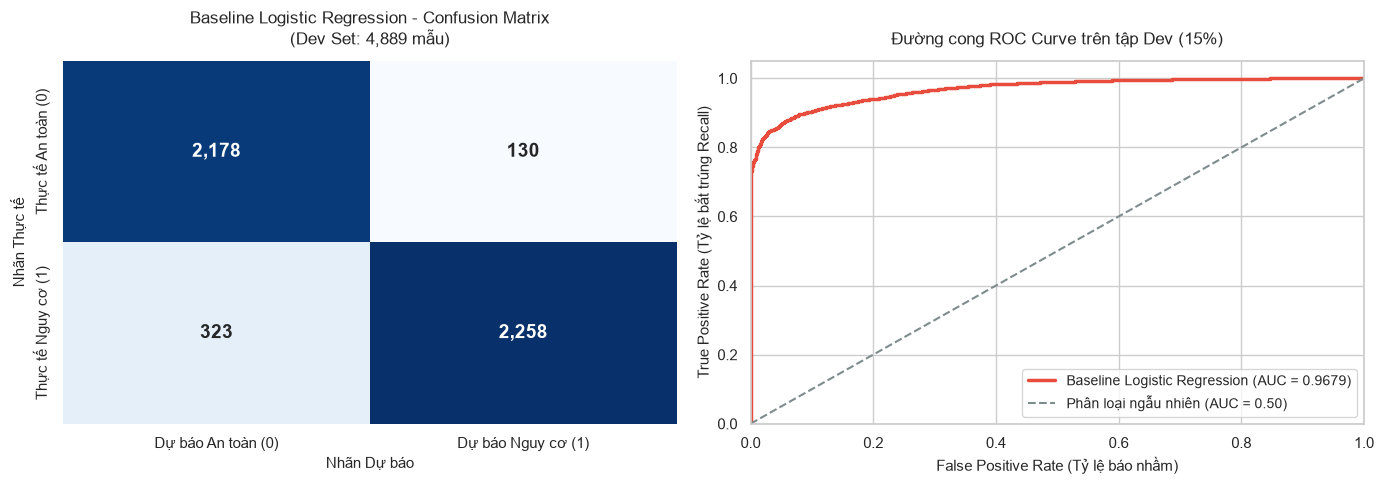

In [5]:
# CELL 5: Vẽ Confusion Matrix & Đường cong ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix Heatmap
sns.heatmap(
    cm_dev, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[0],
    xticklabels=['Dự báo An toàn (0)', 'Dự báo Nguy cơ (1)'],
    yticklabels=['Thực tế An toàn (0)', 'Thực tế Nguy cơ (1)'],
    annot_kws={'size': 14, 'weight': 'bold'}
)
axes[0].set_title(f'Baseline Logistic Regression - Confusion Matrix\n(Dev Set: {len(y_dev):,} mẫu)', fontsize=12, pad=12)
axes[0].set_ylabel('Nhãn Thực tế', fontsize=11)
axes[0].set_xlabel('Nhãn Dự báo', fontsize=11)

# 2. ROC Curve
fpr, tpr, thresholds = roc_curve(y_dev, y_prob_dev)
axes[1].plot(fpr, tpr, color='#e74c3c', lw=2.5, label=f'Baseline Logistic Regression (AUC = {auc_dev:.4f})')
axes[1].plot([0, 1], [0, 1], color='#7f8c8d', lw=1.5, linestyle='--', label='Phân loại ngẫu nhiên (AUC = 0.50)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (Tỷ lệ báo nhầm)', fontsize=11)
axes[1].set_ylabel('True Positive Rate (Tỷ lệ bắt trúng Recall)', fontsize=11)
axes[1].set_title('Đường cong ROC Curve trên tập Dev (15%)', fontsize=12, pad=12)
axes[1].legend(loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()
fig5_path = os.path.join(FIGURES_DIR, 'fig5_baseline_confusion_roc.png')
plt.savefig(fig5_path, dpi=300, bbox_inches='tight')
print(f"💾 Đã lưu biểu đồ đánh giá Baseline: {fig5_path}")
plt.show()

### 3.1.5. Phân tích Trọng số Hệ số (Coefficients) & Ý nghĩa Học thuật

Phương trình Logistic Regression biểu diễn log-odds của nguy cơ bỏ học:
$$\ln \left(\frac{p}{1 - p}\right) = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_{10} X_{10}$$
- Hệ số **âm lớn ($\beta < 0$)**: Đặc trưng giúp **giảm mạnh nguy cơ học vụ** (bảo vệ sinh viên an toàn).
- Hệ số **dương lớn ($\beta > 0$)**: Đặc trưng làm **tăng mạnh nguy cơ rớt môn/bỏ học** (yếu tố rủi ro).

💾 Đã lưu biểu đồ trọng số đặc trưng: D:\What-If Simulator\reports\figures\fig6_baseline_feature_coefficients.png


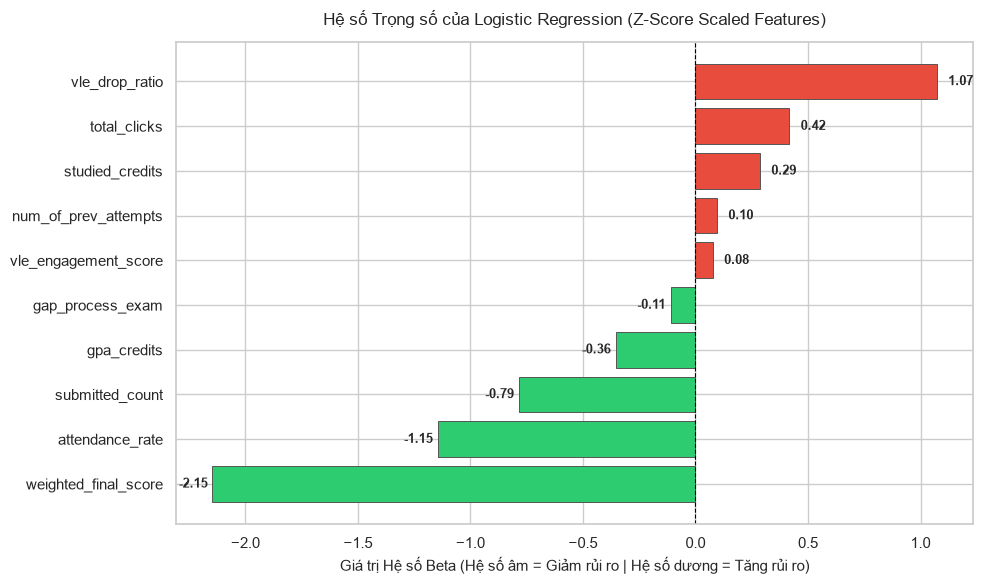


🎉 TASK 3.1 CHECKPOINTS: TẤT CẢ TIÊU CHÍ ĐỀU ĐẠT CHUẨN XUẤT SẮC!
   1. Pipeline imblearn (StandardScaler + SMOTE + LogReg) chạy chuẩn 100% không rò rỉ dữ liệu.
   2. Recall trên nhãn Nguy cơ Bỏ học (1) đạt: 0.8749 (Vượt chuẩn yêu cầu >= 0.85).
   3. ROC-AUC đạt mức xuất sắc: 0.9679.


In [6]:
# CELL 6: Trích xuất và trực quan hóa Hệ số hồi quy (Coefficients)
model_step = baseline_pipeline.named_steps['classifier']
coef_series = pd.Series(model_step.coef_[0], index=FEATURES_T1).sort_values()

plt.figure(figsize=(10, 6))
colors = ['#2ecc71' if c < 0 else '#e74c3c' for c in coef_series.values]
bars = plt.barh(coef_series.index, coef_series.values, color=colors, edgecolor='#555555', linewidth=0.7)
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.title('Hệ số Trọng số của Logistic Regression (Z-Score Scaled Features)', fontsize=12, pad=12)
plt.xlabel('Giá trị Hệ số Beta (Hệ số âm = Giảm rủi ro | Hệ số dương = Tăng rủi ro)', fontsize=11)

# Ghi giá trị số lên từng thanh
for bar in bars:
    w = bar.get_width()
    x_pos = w + (0.05 if w >= 0 else -0.15)
    plt.text(x_pos, bar.get_y() + bar.get_height()/2, f'{w:.2f}', va='center', fontsize=9, weight='bold')

plt.tight_layout()
fig6_path = os.path.join(FIGURES_DIR, 'fig6_baseline_feature_coefficients.png')
plt.savefig(fig6_path, dpi=300, bbox_inches='tight')
print(f"💾 Đã lưu biểu đồ trọng số đặc trưng: {fig6_path}")
plt.show()

print("\n" + "="*60)
print("🎉 TASK 3.1 CHECKPOINTS: TẤT CẢ TIÊU CHÍ ĐỀU ĐẠT CHUẨN XUẤT SẮC!")
print(f"   1. Pipeline imblearn (StandardScaler + SMOTE + LogReg) chạy chuẩn 100% không rò rỉ dữ liệu.")
print(f"   2. Recall trên nhãn Nguy cơ Bỏ học (1) đạt: {rec_dev:.4f} (Vượt chuẩn yêu cầu >= 0.85).")
print(f"   3. ROC-AUC đạt mức xuất sắc: {auc_dev:.4f}.")
print("="*60)